In [1]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
!pip install opencv-python matplotlib
!pip install git+https://github.com/facebookresearch/segment-anything.git


Looking in indexes: https://download.pytorch.org/whl/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 4.8 MB/s eta 0:00:00a 0:00:01
  Cloning https://github.com/facebookresearch/segment-anything.git to /private/var/folders/09/8ljzfvcs0cg5dzgncd1pqmrr0000gp/T/pip-req-build-to0st9pe
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /private/var/folders/09/8ljzfvcs0cg5dzgncd1pqmrr0000gp/T/pip-req-build-to0st9pe
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36590 sha256=fac5910136753223b7c61877086d5b0c08a112ca560b7fd61e177f0232dd5afc
  Stored in directory: /private/var/folders/09/8ljzfvcs0cg5dzgncd1pqmrr0000gp/T/pip-ephem-wheel-cache-mq1i1306/wheels/29/82/ff/04e2be9805a1cb48bec0b85b5a6da6b63f647645750a0e42d4
Successful

In [5]:
import urllib.request

url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"
output_path = "sam_vit_h_4b8939.pth"

urllib.request.urlretrieve(url, output_path)
print("Checkpoint downloaded!.")


Checkpoint downloaded.


In [7]:
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

# Load SAM model
sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

# Create the automatic mask generator
mask_generator = SamAutomaticMaskGenerator(sam)


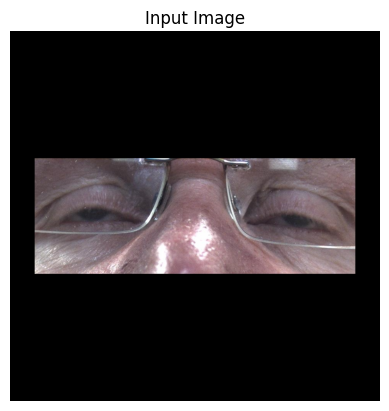

In [13]:
import cv2
import matplotlib.pyplot as plt

def load_image(image_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image

# Example: Replace with a real image path
image = load_image("test_image.jpg")

plt.imshow(image)
plt.title("Input Image")
plt.axis('off')
plt.show()


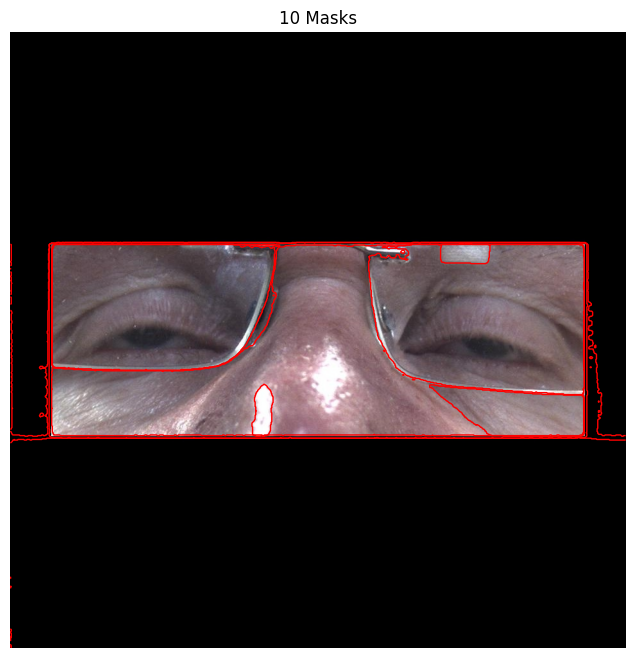

In [15]:
masks = mask_generator.generate(image)

# Visualize masks
def show_masks(image, masks):
    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    for mask in masks:
        plt.contour(mask['segmentation'], colors='r', linewidths=1)
    plt.axis('off')
    plt.title(f'{len(masks)} Masks')
    plt.show()

show_masks(image, masks)

In [28]:
# Define an overlay function
import matplotlib.pyplot as plt
import numpy as np

def show_mask_overlay(image, masks):
    for i, mask in enumerate(masks):
        segmentation = mask['segmentation']  # boolean mask
        
        # Create a color overlay (e.g., red with transparency)
        overlay = np.zeros_like(image, dtype=np.uint8)
        overlay[segmentation] = [255, 0, 0]  # Red where mask is True

        # Combine original image and overlay using alpha blending
        alpha = 0.5
        blended = image.copy()
        blended = (blended * (1 - alpha) + overlay * alpha).astype(np.uint8)

        # Plot
        plt.figure(figsize=(6, 6))
        plt.imshow(blended)
        plt.title(f"Mask {i}")
        plt.axis('off')
        plt.show()


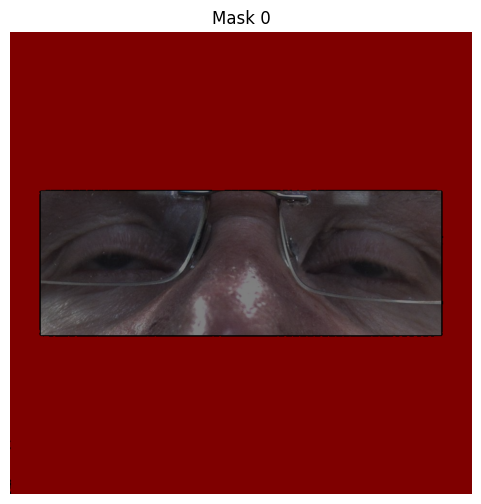

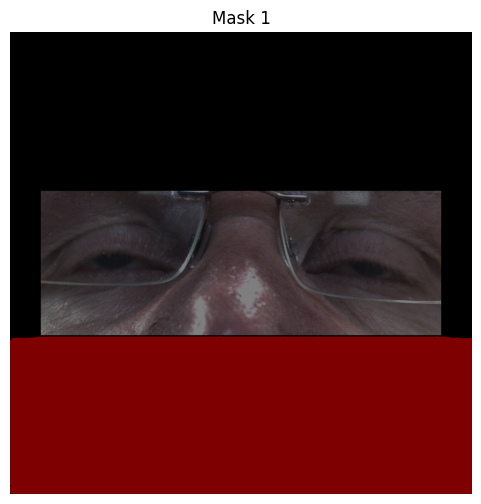

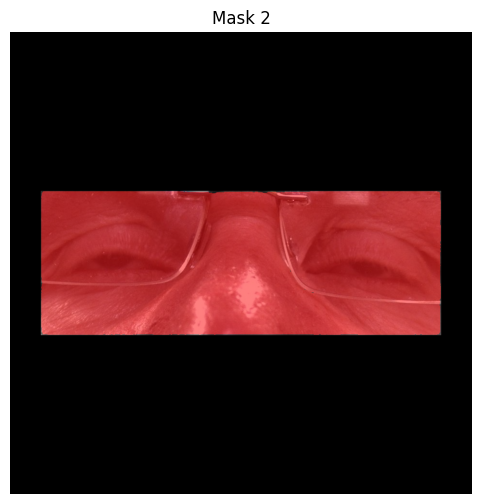

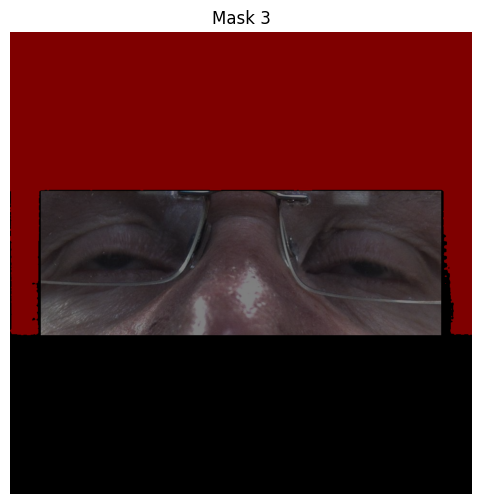

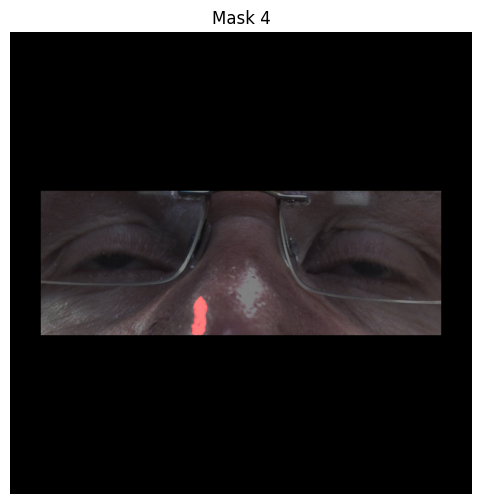

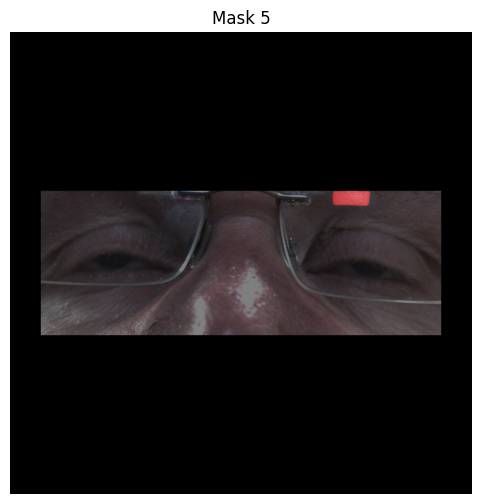

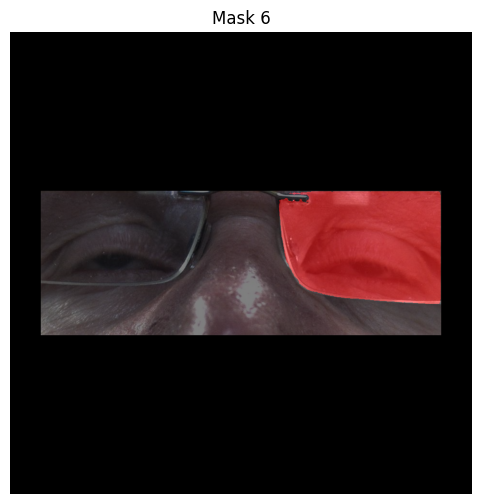

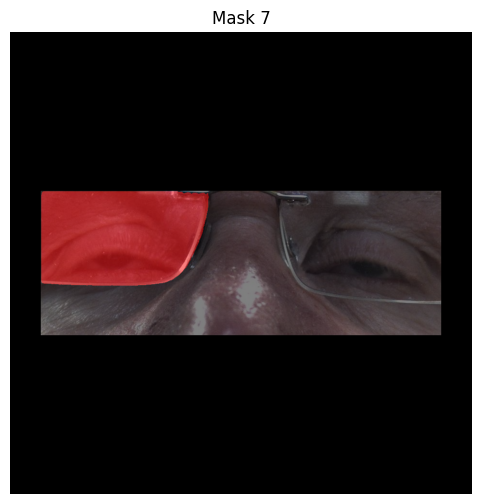

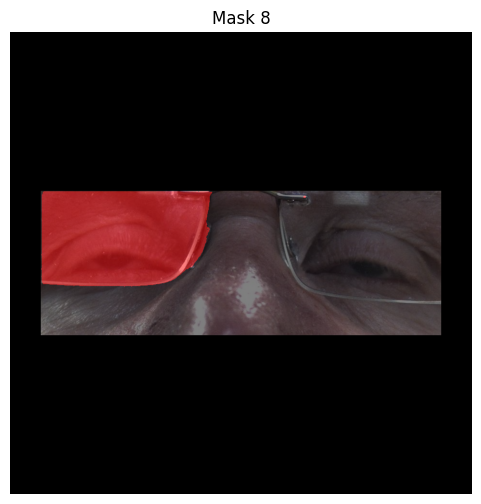

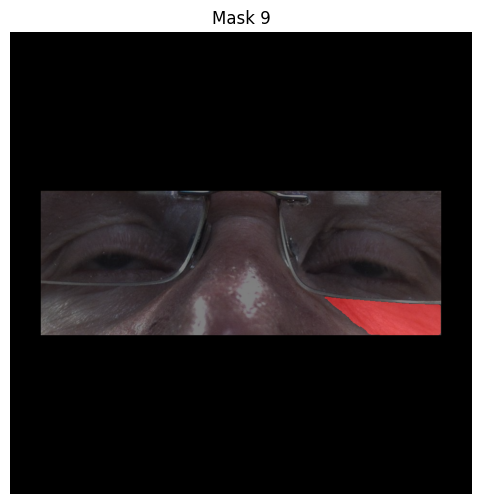

In [30]:
show_mask_overlay(image, masks)

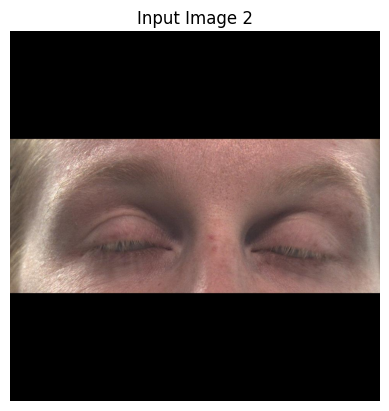

In [24]:
image2 = load_image("test_image_2.jpg")

plt.imshow(image2)
plt.title("Input Image 2")
plt.axis('off')
plt.show()
masks2 = mask_generator.generate(image2)



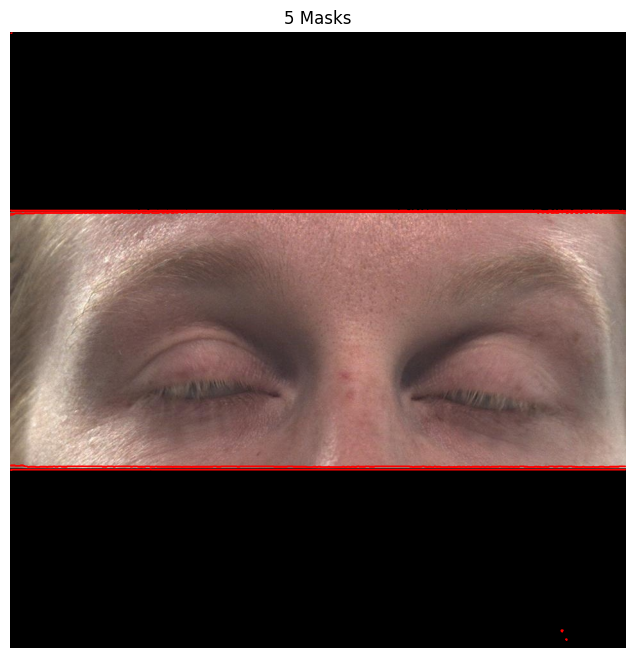

In [26]:
show_masks(image2, masks2)

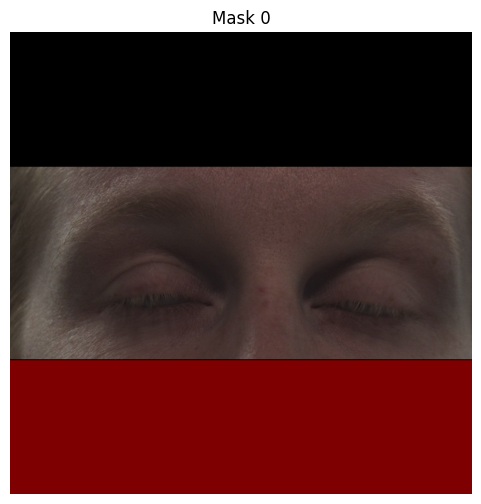

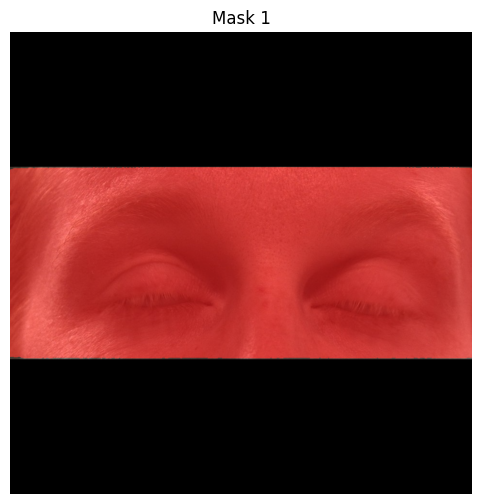

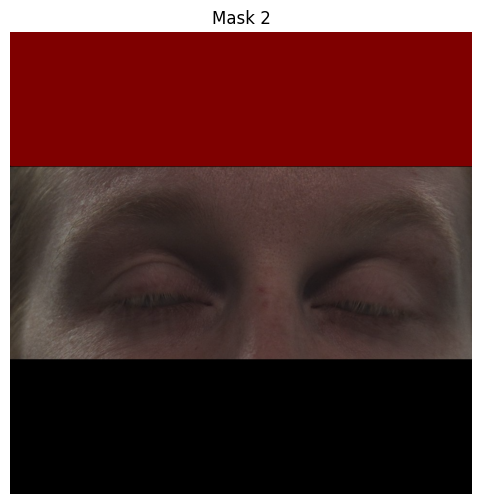

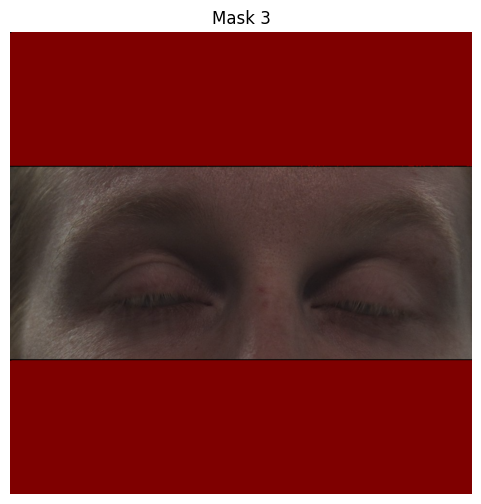

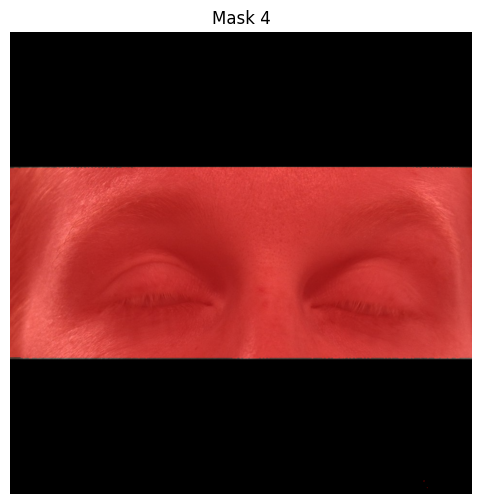

In [32]:
show_mask_overlay(image2, masks2)

## I feel like better masks could be generated if I use the coordinates x1,x2,y1,y2 of the eye centers

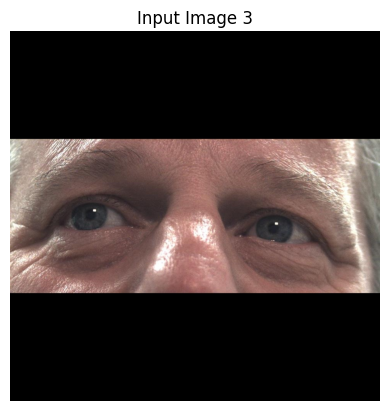

In [35]:
image3 = load_image("test_image_3.jpg")

plt.imshow(image3)
plt.title("Input Image 3")
plt.axis('off')
plt.show()
masks3 = mask_generator.generate(image3)


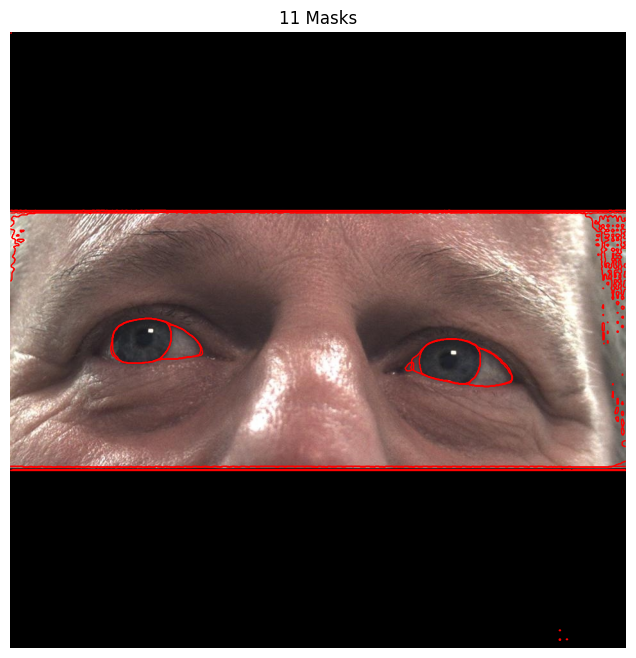

In [36]:
show_masks(image3, masks3)

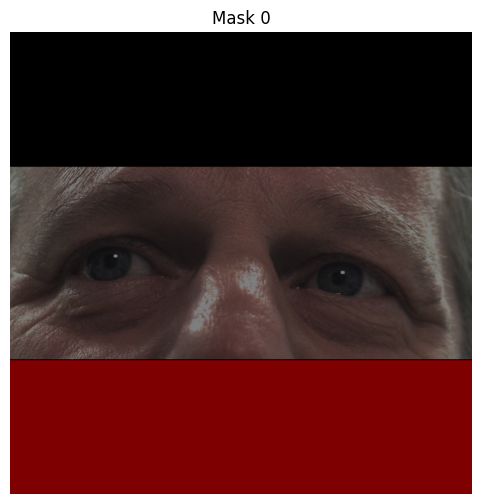

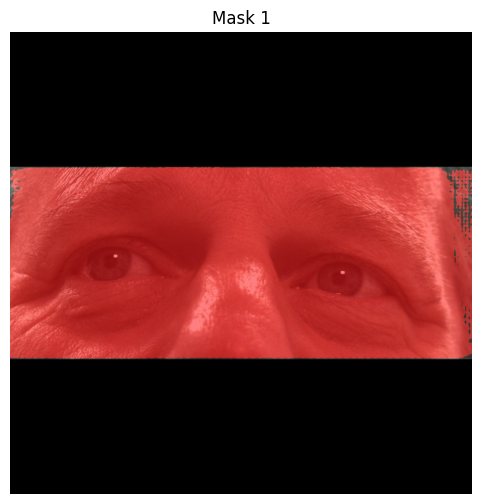

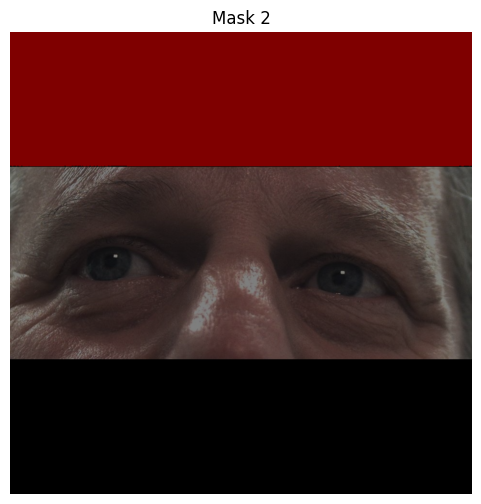

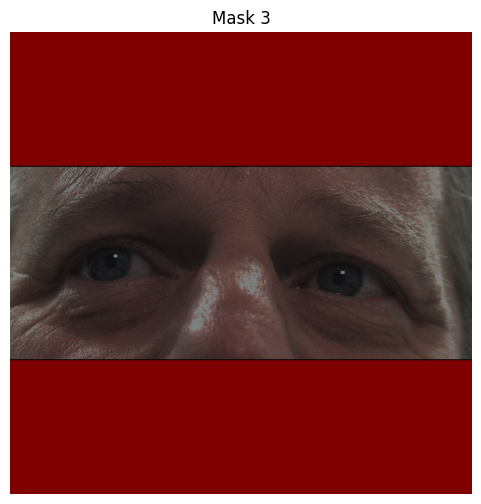

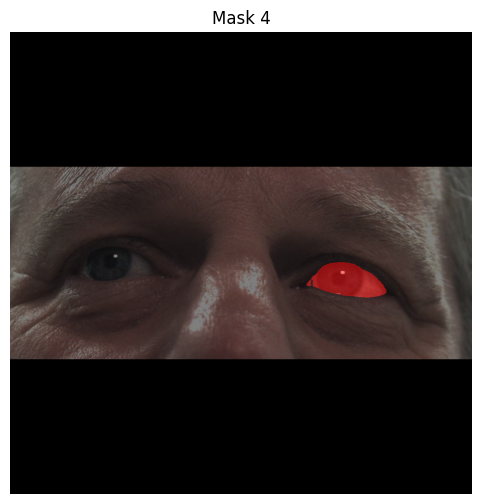

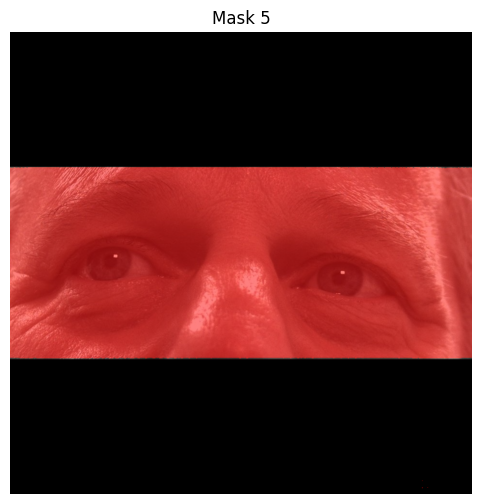

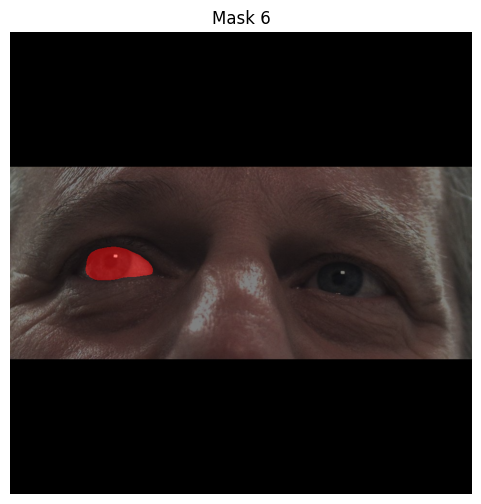

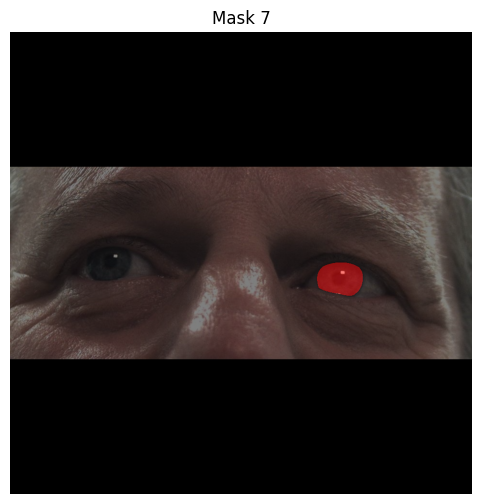

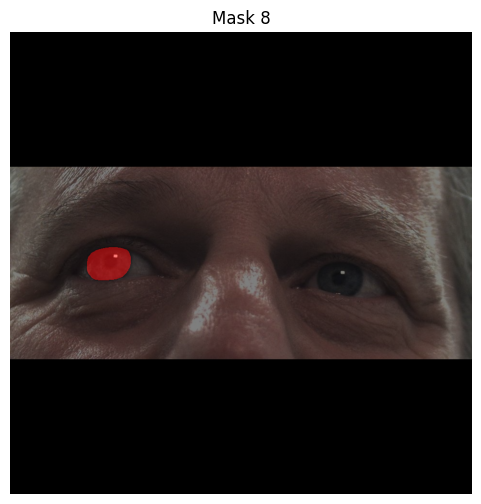

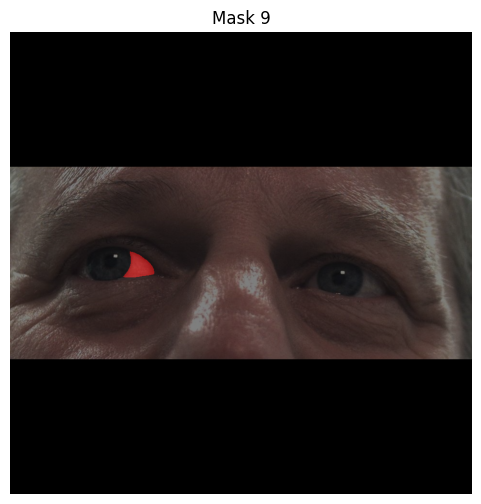

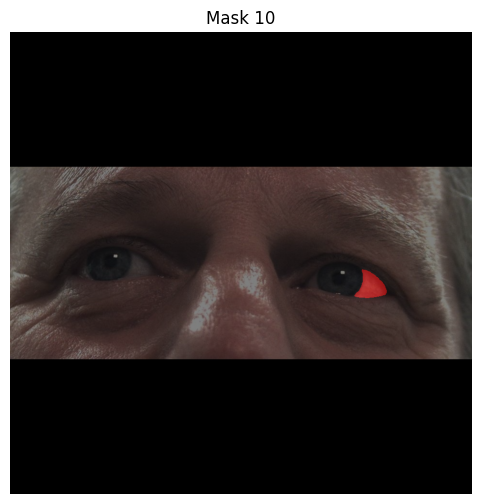

In [39]:
show_mask_overlay(image3, masks3)

In [43]:
import pandas as pd
eye_centers_17_0 = pd.read_csv("Eye_center_Localization_labels/017_0.csv")

In [45]:
eye_centers_17_0.head()

,Unnamed: 0,filename,LE_left,LE_top,LE_right,LE_bottom,RE_left,RE_top,RE_right,RE_bottom,lx,ly,rx,ry,relative_lx,relative_ly,relative_rx,relative_ry
0,0,017/0/2022-10-03 10:15:05.727075-84.jpg,191,455,442,585,627,484,855,593,346,520,783,541,155,65,156,57
1,1,017/0/2022-10-03 10:16:19.381598-11840.jpg,187,454,435,584,619,473,851,587,285,506,720,522,98,52,101,49
2,2,017/0/2022-10-03 10:16:51.087983-16912.jpg,183,466,437,587,618,490,840,595,329,527,768,541,146,61,150,51
3,3,017/0/2022-10-03 10:19:20.564934-40780.jpg,143,496,408,617,583,501,821,626,18,14,18,14,-125,-482,-565,-487
4,4,017/0/2022-10-03 10:15:48.509613-6928.jpg,181,459,421,587,615,477,844,592,265,522,705,539,84,63,90,62


In [47]:
import pandas as pd

def transform_filename(value):
    try:
        # Example: "017/0/2022-10-03 10:15:05.727075-84"
        parts = value.split('/')
        if len(parts) < 3:
            return None

        datetime_zone = parts[2]  # "2022-10-03 10:15:05.727075-84"
        if '-' not in datetime_zone:
            return None

        datetime_part, zone_part = datetime_zone.rsplit('-', 1)
        date, time = datetime_part.split(' ')
        time_main, micros = time.split('.')
        time_formatted = time_main.replace(':', '/')
        micros = micros[:6].ljust(6, '0')  # normalize microseconds
        zone_digit = zone_part[0] if zone_part else '0'

        return f"{date} {time_formatted}.{micros}-{zone_digit}"

    except Exception as e:
        return f"Error: {e}"

# Apply transformation
eye_centers_17_0['filename_formatted'] = eye_centers_17_0['filename'].apply(transform_filename)

print(eye_centers_17_0['filename_formatted'].head())

# Save the result (optional)
# eye_centers_17_0.to_csv("your_file_with_formatted_filenames.csv", index=False)


0    2022-10-03 10/15/05.727075-8
1    2022-10-03 10/16/19.381598-1
2    2022-10-03 10/16/51.087983-1
3    2022-10-03 10/19/20.564934-4
4    2022-10-03 10/15/48.509613-6
Name: filename_formatted, dtype: object


In [49]:
eye_centers_17_0.to_csv("017_0_formatted.csv", index=False)

In [ ]:
x1=
y1=
x2=
y2=

In [ ]:
## Use code after feeding eye center coordinates x1,x2,y1,y2
# Use small bounding box (“bubble”) around the eye center coordinates

padding = 20  # pixels, adjust as needed

x_min = max(min(x1, x2) - padding, 0)
y_min = max(min(y1, y2) - padding, 0)
x_max = max(x1, x2) + padding
y_max = max(y1, y2) + padding

eye_box = np.array([x_min, y_min, x_max, y_max])


masks, scores, logits = predictor.predict(
    box=eye_box,
    multimask_output=True  # Returns multiple mask proposals (usually 3)
)

import matplotlib.pyplot as plt

plt.imshow(image)
plt.imshow(masks[0], alpha=0.5)  # Overlay with 50% transparency
plt.title("Mask predicted from eye bounding box")
plt.axis('off')
plt.show()
